# Notebook 1: Oracle (ORCL) Market Data, Candlestick Charts and Data Quality

| Key | Value |
|:----|:------|
| **Stock** | Oracle Corporation (ORCL) |
| **Data source** | Yahoo Finance, downloaded with `python download_data.py --target ORCL` on 22 November 2026 |
| **Period** | 2 January 2015 to 9 November 2026 |
| **Based on** | 1_market_data_and_candlesticks.ipynb, adapted to our stock |

## What this notebook does

Our client, a portfolio manager, wants to know whether we can forecast Oracle's closing price better than the simplest forecast: "tomorrow will be the same as today". Before we build any model, this notebook checks that the Oracle data is complete and clean, and looks at how the stock and the predictor markets behave.

## Step 1: Set Up the Notebook

In [1]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

# Google Colab starts with an empty workspace, so we fetch the lab files first.
# This block does nothing in your local environment (your laptop).
if "google.colab" in sys.modules and not os.path.exists("tslab"):

    # Run the command "git clone <url>" to download the course repository
    # into a new folder in the current directory.
    # Each list item is one argument, so no shell is involved and spaces do not need quoting.
    # check=True raises an error (CalledProcessError) if the command fails,
    # e.g. no network or the folder already exists, instead of failing silently.
    subprocess.run(["git", "clone", "https://github.com/course-files/TimeSeriesForecastingandNeuralNetworks.git"], check=True)

    # Relative paths start from the folder specified. Example: `pd.read_csv("data/prices.csv")`
    # now looks for <named_folder>/data/prices.csv. This is why requirements/colab.txt works
    # in the next line.
    os.chdir("TimeSeriesForecastingandNeuralNetworks")

    # Install the packages listed in requirements/colab.txt.
    # sys.executable is the full path to the Python running this notebook, so
    # "-m pip" uses that interpreter's pip and installs into the same environment.
    # -q (quiet) cuts down pip's output; -r reads the package list from the file.
    # check=True stops the notebook with an error if the installation fails.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/colab.txt"], check=True)
    print("Colab workspace prepared.")

Python interpreter: c:\Users\desmo\Documents\BI-COURSEWORK\TimeSeries-Lab-202604-c4\.venv\Scripts\python.exe
Python version    : 3.12.10


In [2]:
# Data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
from IPython.display import Image, display

# Our own helper package (see the `tslab` folder)
from tslab import config
from tslab.data import load_market_data, data_quality_report

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

## Step 2: The Target and the Predictors

The **target** is Oracle's daily closing price. The **predictors** are the other markets we give the model.

In [3]:
print("Target stock:", config.TARGET_TICKER)
display(pd.DataFrame({"Yahoo Finance symbol": config.PREDICTOR_TICKERS}))

Target stock: ORCL


,Yahoo Finance symbol
SP500,^GSPC
TECH,XLK
VIX,^VIX
US10Y,^TNX
USD,DX-Y.NYB
BRENT,BZ=F
GOLD,GC=F


| Predictor | Yahoo Finance | What it measures | How to read it and why it matters for the forecast |
|:----------|:--------------|:-----------------|:---------------------------------------------------|
| **SP500** | [^GSPC](https://finance.yahoo.com/quote/%5EGSPC/) | The broad US stock market | **Up** = the overall market is gaining. Most stocks move with the market, so this is usually the strongest single predictor. |
| **TECH** | [XLK](https://finance.yahoo.com/quote/XLK/) | An Exchange Traded Fund (ETF) holding technology companies | **Up** = technology stocks are gaining as a group. Captures the behaviour of the stock's own sector, beyond the general market. |
| **VIX** | [^VIX](https://finance.yahoo.com/quote/%5EVIX/) | The market's expected volatility over the next 30 days (the "fear index") | **Up** = investors expect larger swings, usually during sell-offs. Below 15 is calm, above 30 is crisis-level. Tends to move opposite to stock prices. |
| **US10Y** | [^TNX](https://finance.yahoo.com/quote/%5ETNX/) | The yield on 10-year US government bonds, in percent | **Up** = borrowing is more expensive and safe bonds pay more. Future company profits become less attractive by comparison, which often pressures technology stocks. |
| **USD** | [DX-Y.NYB](https://finance.yahoo.com/quote/DX-Y.NYB/) | The US dollar against a basket of six major currencies | **Up** = the dollar is stronger. Overseas sales are worth fewer dollars, which can reduce reported profits for multinational companies. |
| **BRENT** | [BZ=F](https://finance.yahoo.com/quote/BZ%3DF/) | The price of Brent crude oil, in US dollars per barrel | **Up** = stronger demand or higher energy costs. Signals economic activity, but sharp rises can also squeeze company margins. |
| **GOLD** | [GC=F](https://finance.yahoo.com/quote/GC%3DF/) | The price of gold, in US dollars per troy ounce | **Up** = investors are seeking safety or protection against inflation. Often rises when confidence in stocks falls. |

**Why we chose Oracle:** Oracle is a large US technology company, so the predictors above have a clear link to its price: it moves with the S&P 500 and the technology fund, and like other tech stocks it is sensitive to interest rates and the US dollar. It has traded for the whole snapshot period, which gives us almost 12 years of daily data and enough history for the walk-forward settings used in the later notebooks. Its price has also had some sharp moves in recent years, which makes it a fair test of whether a model can beat the naive forecast.

## Step 3: Load the Data and Check Its Quality

In [4]:
data = load_market_data()
data.head()

Loaded 2981 trading days of ORCL, 2015-01-02 to 2026-11-09, with 7 predictor series.


,Open,High,Low,Close,Volume,SP500,TECH,VIX,US10Y,USD,BRENT,GOLD
Date,,,,,,,,,,,,
2015-01-02,37.664154,37.806376,36.785715,37.086895,15070200,2058.199951,18.041681,17.790001,2.123,91.080002,56.419998,1186.000000
2015-01-05,37.044941,37.120441,36.558393,36.566780,18369400,2020.579956,17.766272,19.920000,2.039,91.379997,53.110001,1203.900024
2015-01-06,36.961041,37.061706,36.063440,36.189270,19229500,2002.609985,17.552059,21.120001,1.963,91.500000,51.099998,1219.300049
2015-01-07,36.348672,36.508059,36.080228,36.197674,13502200,2025.900024,17.700693,19.309999,1.954,91.889999,51.150002,1210.599976
2015-01-08,36.600345,36.860396,36.390625,36.415791,17516900,2062.139893,18.089769,17.010000,2.016,92.370003,50.959999,1208.400024


In [5]:
data.tail()

,Open,High,Low,Close,Volume,SP500,TECH,VIX,US10Y,USD,BRENT,GOLD
Date,,,,,,,,,,,,
2026-11-03,122.000000,128.139999,121.349998,126.190002,84295400,7568.919922,176.509995,20.830000,4.952,101.870003,103.599998,3940.399902
2026-11-04,121.779999,129.850006,121.779999,123.730003,111828100,7688.620117,176.500000,16.610001,4.894,101.510002,94.620003,4073.000000
2026-11-05,123.000000,124.239998,111.660004,115.160004,56875900,7353.729980,162.380005,28.180000,4.837,101.550003,98.290001,4113.500000
2026-11-06,119.540001,119.699997,109.209999,116.099998,47603100,7376.859863,164.740005,25.639999,4.859,102.300003,98.320000,4074.899902
2026-11-09,117.029999,120.260002,114.910004,119.790001,27724800,7549.939941,170.880005,19.920000,4.864,101.650002,92.570000,4114.500000


In [6]:
print("The number of observations and variables:", data.shape)
print()
data.info()

The number of observations and variables: (2981, 12)

<class 'pandas.DataFrame'>
DatetimeIndex: 2981 entries, 2015-01-02 to 2026-11-09
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    2981 non-null   float64
 1   High    2981 non-null   float64
 2   Low     2981 non-null   float64
 3   Close   2981 non-null   float64
 4   Volume  2981 non-null   int64  
 5   SP500   2981 non-null   float64
 6   TECH    2981 non-null   float64
 7   VIX     2981 non-null   float64
 8   US10Y   2981 non-null   float64
 9   USD     2981 non-null   float64
 10  BRENT   2981 non-null   float64
 11  GOLD    2981 non-null   float64
dtypes: float64(11), int64(1)
memory usage: 302.8 KB


In [7]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Open,2981.0,8.177483e+01,5.583724e+01,2.879141e+01,4.194178e+01,5.587934e+01,1.106403e+02,3.254138e+02
High,2981.0,8.282238e+01,5.682479e+01,2.915770e+01,4.243341e+01,5.637818e+01,1.117271e+02,3.405644e+02
Low,2981.0,8.066000e+01,5.453481e+01,2.822070e+01,4.154157e+01,5.503061e+01,1.096648e+02,3.074359e+02
Close,2981.0,8.172540e+01,5.564113e+01,2.891067e+01,4.196845e+01,5.576889e+01,1.107196e+02,3.234337e+02
Volume,2981.0,1.413542e+07,1.023137e+07,2.168200e+06,8.009800e+06,1.131660e+07,1.646910e+07,1.316181e+08
SP500,2981.0,3.880456e+03,1.598001e+03,1.829080e+03,2.579850e+03,3.626910e+03,4.697960e+03,7.818930e+03
TECH,2981.0,6.544416e+01,4.442270e+01,1.662293e+01,2.919654e+01,5.863794e+01,8.969332e+01,2.020000e+02
VIX,2981.0,1.832457e+01,6.928125e+00,9.140000e+00,1.376000e+01,1.664000e+01,2.103000e+01,8.269000e+01
US10Y,2981.0,2.778144e+00,1.200831e+00,4.990000e-01,1.814000e+00,2.508000e+00,4.033000e+00,5.311000e+00
USD,2981.0,9.840886e+01,4.714785e+00,8.859000e+01,9.506000e+01,9.787000e+01,1.016100e+02,1.141100e+02


In [8]:
# A short report of the problems that most often break a forecasting project
data_quality_report(data)

rows                               2981
first_date                   2015-01-02
last_date                    2026-11-09
duplicate_dates                       0
missing_values                        0
non_positive_prices                   0
days_with_zero_volume                 0
high_below_low                        0
longest_gap_in_days                   4
days_with_move_over_10pct            18
dtype: object

In [9]:
# The days on which the closing price moved by more than 10% from the day before
moves = data["Close"].pct_change()
big = moves[moves.abs() > 0.10].sort_values()
print(f"{len(big)} days with a move of more than 10%")
(big * 100).round(1).rename("move (%)").to_frame()

18 days with a move of more than 10%


,move (%)
Date,
2025-01-27,-13.8
2023-09-12,-13.5
2023-12-12,-12.4
2020-03-12,-11.0
2020-03-16,-10.9
2025-12-11,-10.8
2022-06-14,10.4
2026-10-28,10.7
2026-05-29,10.8


**Our finding:** The data quality report shows no duplicate dates, no missing values, no prices at or below zero, no days with zero volume and no days where the high is below the low. The longest gap between trading days is 4 days, which is a long weekend, so no trading days are missing.

There are 18 days on which Oracle's closing price moved by more than 10%. We checked the news for each of them, and all of them are real market events, not data errors, so we keep them:

| Cause | Days | Example |
|:------|:-----|:--------|
| Quarterly earnings reports (the day after results) | 10 | The biggest move of all: +35.9% on 10 September 2025, after Oracle reported a huge order backlog for its AI cloud business. Falls of 13.5% (Sep 2023), 12.4% (Dec 2023) and 10.8% (Dec 2025) came when revenue missed expectations or spending on AI data centres rose faster than investors wanted. |
| The COVID-19 market crash | 3 | -11.0% on 12 March 2020, +20.4% on 13 March 2020 and -10.9% on 16 March 2020 |
| Market-wide events | 2 | -13.8% on 27 January 2025 (the sell-off in AI stocks after DeepSeek's low-cost AI model) and +12.2% on 9 April 2025 (the rally when US tariffs were paused) |
| Company news and investor sentiment | 3 | +12.7% on 13 April 2026 (a software rebound and new AI product announcements), +10.8% on 29 May 2026 (analyst upgrades) and +10.7% on 28 October 2026 (Investor Day, with new long-term revenue targets) |

Most of the big moves are recent: 11 of the 18 happened from 2024 onwards, when Oracle became an AI cloud stock. This matters for forecasting. Earnings news arrives without warning, and none of our predictors can see it coming, so no model is likely to predict these jumps. It also means Oracle has been much more volatile in recent years than in the early part of the data.

## Step 4: Candlestick Chart

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


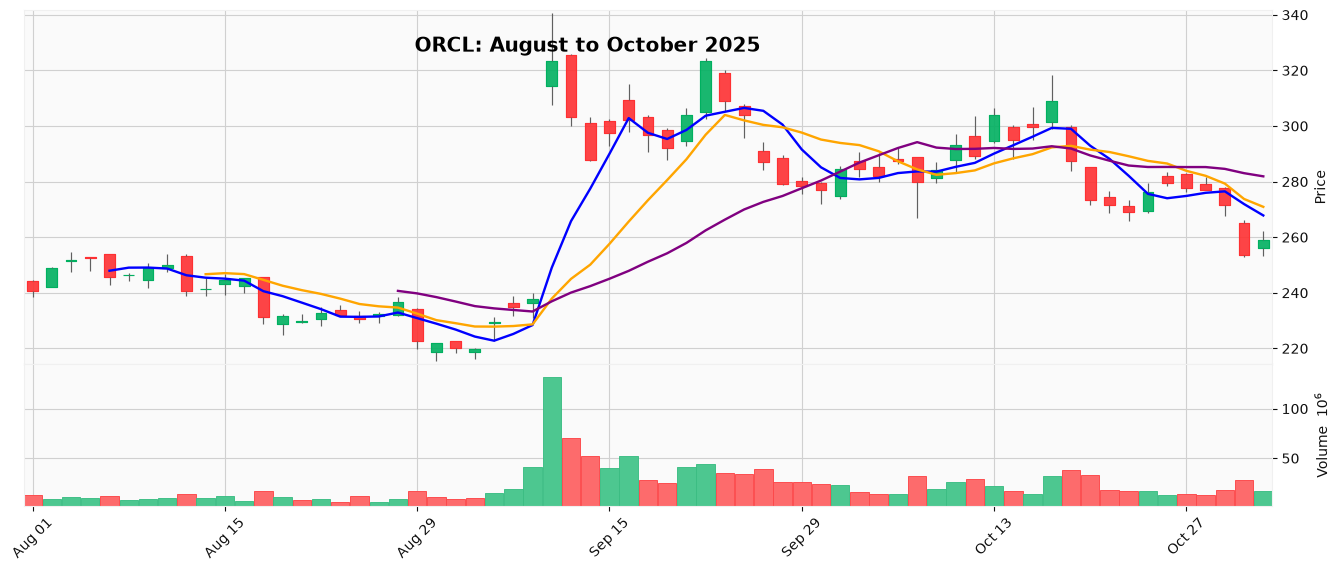

In [10]:
# A period of our choice: August to October 2025, with volume and 5-, 10- and 20-day moving averages
# [fill in: change the dates if the group prefers another period]
recent = data.loc["2025-08-01":"2025-10-31", ["Open", "High", "Low", "Close", "Volume"]]
mpf.plot(
    recent, type="candle", style="yahoo", volume=True,
    mav=(5, 10, 20), mavcolors=["blue", "orange", "purple"],
    figratio=(25, 10), tight_layout=True,
    title=f"{config.TARGET_TICKER}: August to October 2025",
)

**Our finding:** We chose August to October 2025 because it contains Oracle's biggest single-day move in the whole dataset.

- **August:** The price drifted down slowly, from about 250 to about 220 by early September. Volume was low and steady, and the 5-, 10- and 20-day moving averages sat close together, which shows a quiet period with no clear trend.
- **10 September:** After its quarterly earnings report, Oracle opened far above the previous close, a gap of more than 30%, and briefly traded near 340. Volume was several times higher than on any other day in the chart. The candle and volume bar show a sudden jump on news, not a gradual build-up.
- **After the jump:** The price did not keep rising. It fell back towards 300 over the next few days, rose again to about 320 in late September, and then slid steadily through October to about 255 by the end of the month, giving back more than half of the jump. The 5-day moving average crossed below the 20-day average in early October and again at the end of the month, which signals the uptrend fading.

This period shows two things that matter for forecasting. First, the biggest move came overnight, on news that no predictor in our data could see in advance, so no model would have forecast it. Second, a big jump was followed by weeks of choppy, large daily moves, which is the volatility clustering we look at in Step 6.

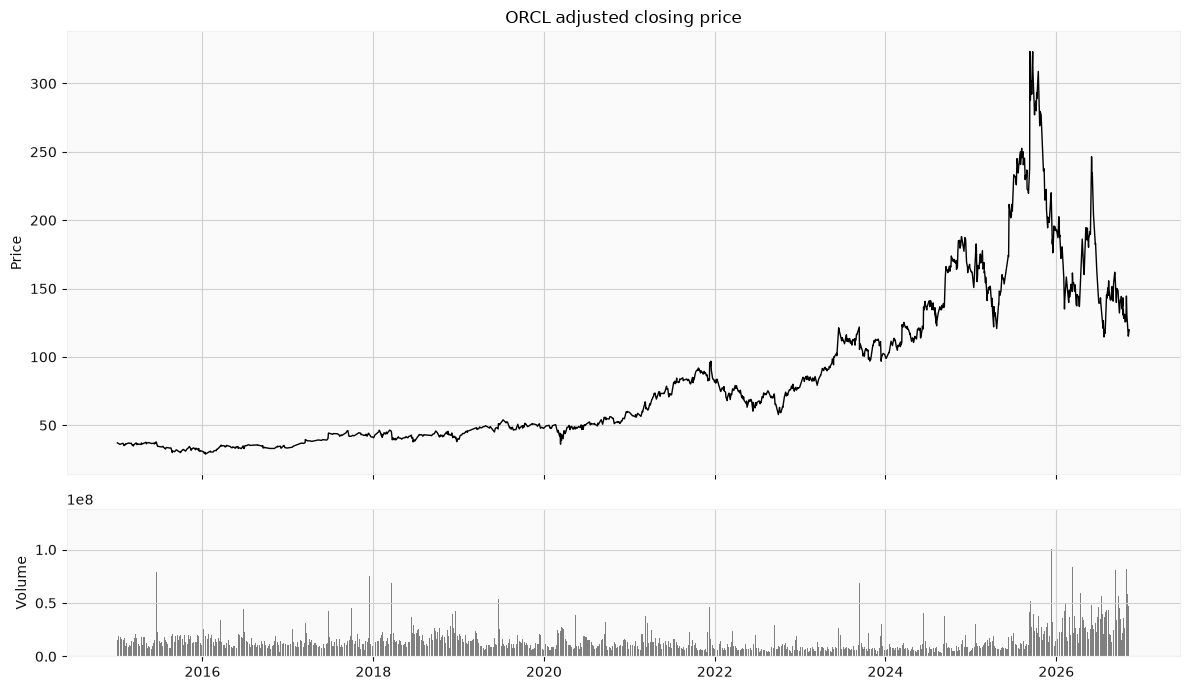

In [11]:
# The whole history of the closing price, with volume underneath

# sharex=True links the horizontal x-axis of both subplots so that zooming or panning on one automatically
# aligns with the other (sharing the same date timeline).
# gridspec_kw={"height_ratios": [3, 1]} allocates 75% of the total vertical height to the top plot (for the
# price line) and 25% to the bottom plot (for the volume bars).
fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
top.plot(data["Close"], color="black", linewidth=1)
top.set_title(f"{config.TARGET_TICKER} adjusted closing price")
top.set_ylabel("Price")
bottom.bar(data.index, data["Volume"], color="grey", width=1.5)
bottom.set_ylabel("Volume")
plt.tight_layout()
plt.show()

**Our finding:** Over the whole period, Oracle's price went through two very different phases.

- **2015 to 2022, slow and steady:** The price stayed between about 35 and 50 from 2015 to 2020, with only a short dip in the March 2020 crash. It then rose to about 95 by the end of 2021, fell back to about 60 during the 2022 market downturn, and recovered.
- **2023 to 2026, fast and volatile:** From 2023 the price rose much faster as Oracle became an AI cloud company, passing 100 in 2023 and reaching about 180 by late 2024. It peaked at over 300 in September 2025, then lost more than half its value by early 2026. It rebounded to about 245 in mid-2026 and fell again to about 120 by November 2026.

The volume chart tells the same story. Trading was low and steady for most of the period, and became much heavier and more erratic from late 2025, when the price swings were largest.

The price clearly trends and changes its behaviour over time, so it is not stationary. Notebook 2 tests this formally. It also means the last two years, which matter most for our forecast, look very different from the years a model would train on first.

## Step 5: Oracle Compared With the Predictors

Each series is rebased to 100 on the first day (divided by its first value and multiplied by 100), so that series measured in different units can be compared on one chart.

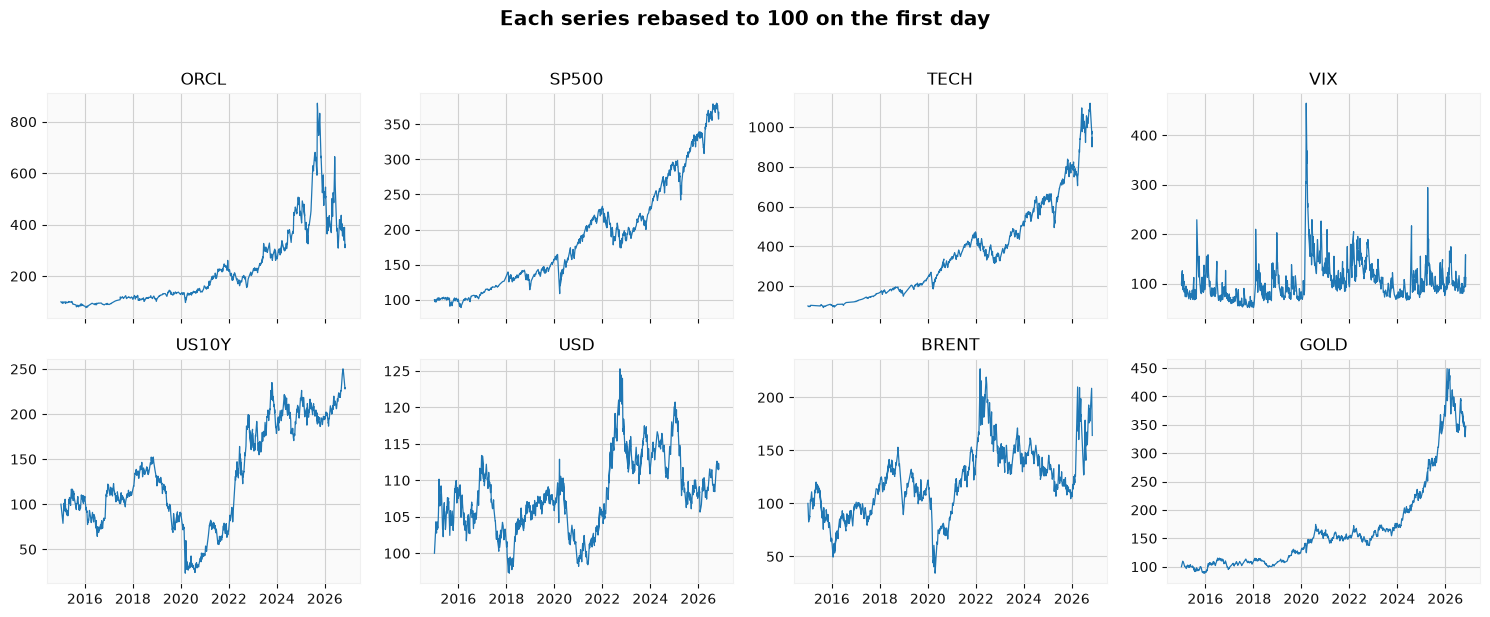

In [12]:
others = list(config.PREDICTOR_TICKERS.keys())
rebased = data[["Close"] + others].copy()
rebased = rebased / rebased.iloc[0] * 100
rebased = rebased.rename(columns={"Close": config.TARGET_TICKER})

fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True)
for ax, column in zip(axes.ravel(), rebased.columns):
    ax.plot(rebased[column], linewidth=0.9)
    ax.set_title(column)
plt.suptitle("Each series rebased to 100 on the first day", y=1.02)
plt.tight_layout()
plt.show()

**Our finding:** Since January 2015, the technology fund (TECH) rose the most of the predictors, to about 10 times its starting level, ahead of gold (about 3.5 times) and the S&P 500 (about 3.7 times). Oracle itself peaked at about 8.7 times its starting level in September 2025 and ended at about 3.2 times.

Oracle looks most like TECH and the S&P 500: all three rise slowly until about 2020 and then much faster. The difference is that Oracle's rise came later and was far more extreme, with a sharp spike in 2025 and a fall of more than half afterwards, which the broad market and the technology fund did not have.

The other series behave differently:
- **VIX** has no trend. It stays around its starting level, with sharp spikes during crises, the biggest in March 2020.
- **US10Y** (the interest rate) fell to about a quarter of its starting level in 2020 and then more than doubled from 2022.
- **USD** moves within a narrow band, never more than about 25% above where it started.
- **BRENT** crashed in 2020, spiked in 2022 and has been volatile since.
- **GOLD** was flat until 2019 and has risen sharply since 2024.

Gold is a good warning. It rose strongly in the same years as Oracle, so the two look related on this chart, even though there is no obvious reason why gold should drive Oracle's price. Series that trend in the same direction for years will look related even if they are not, so these charts are not evidence that a predictor will help the forecast. Notebook 4 tests that properly.

## Step 6: Daily Log Returns

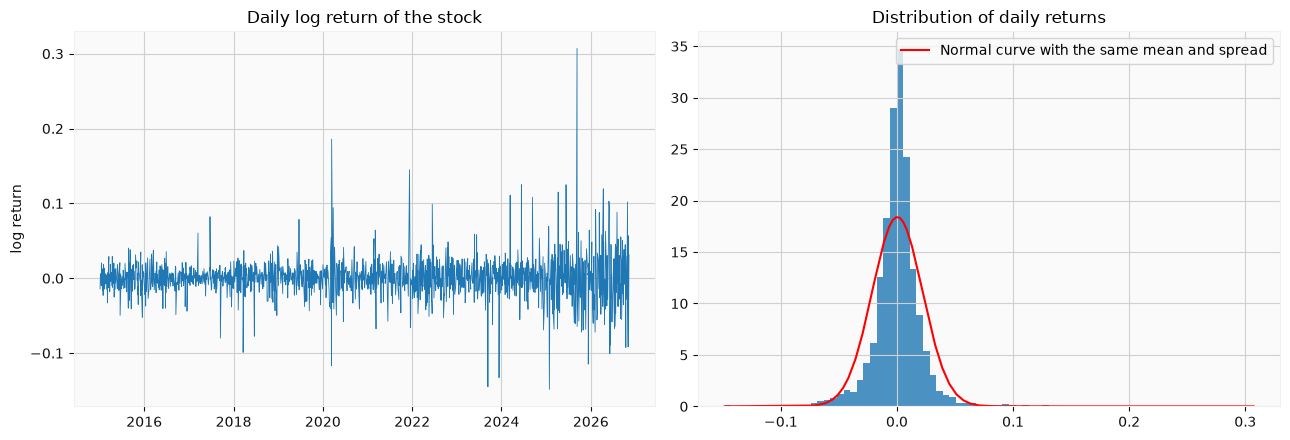

Mean daily return      : 0.00039
Standard deviation     : 0.02167
Largest one-day gain   : 0.3071
Largest one-day loss   : -0.1484


In [13]:
data["log_return"] = np.log(data["Close"]).diff()
daily = data["log_return"].dropna()

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5))
left.plot(daily, linewidth=0.6, color="tab:blue")
left.set_title("Daily log return of the stock")
left.set_ylabel("log return")

right.hist(daily, bins=80, color="tab:blue", alpha=0.8, density=True)
grid = np.linspace(daily.min(), daily.max(), 300)
normal_curve = np.exp(-0.5 * ((grid - daily.mean()) / daily.std()) ** 2) / (daily.std() * np.sqrt(2 * np.pi))
right.plot(grid, normal_curve, color="red", label="Normal curve with the same mean and spread")
right.set_title("Distribution of daily returns")
right.legend()
plt.tight_layout()
plt.show()

print(f"Mean daily return      : {daily.mean():.5f}")
print(f"Standard deviation     : {daily.std():.5f}")
print(f"Largest one-day gain   : {daily.max():.4f}")
print(f"Largest one-day loss   : {daily.min():.4f}")

**Our finding:** Oracle's daily log return moves around zero with no trend. The average daily log return is 0.00039 (about 0.04% a day, or roughly 10% a year), and the standard deviation is 0.0217, so a typical day moves the price by about 2%. The average is tiny compared with the daily swings, which is why forecasting the next day's return is so hard.

The largest one-day gain was a log return of 0.307 (+35.9%, on 10 September 2025), and the largest one-day loss was -0.148 (-13.8%, on 27 January 2025). Both came in 2025.

The left chart shows volatility clustering: calm periods and wild periods come in groups. Returns were calm from 2015 to 2019, burst out in March 2020, settled again from 2021 to 2023, and became much wilder from 2024, with more large days in 2025 and 2026 than in any earlier period.

The histogram shows fat tails. Compared with the red normal curve, there are more days with almost no change (the tall, narrow peak) and more extreme days far out in the tails. A normal distribution with the same mean and spread would make a +35.9% day almost impossible, but Oracle had one. Any method that assumes normal errors will underestimate how often very large moves happen.

The returns, unlike the price, have a stable average around zero, so we forecast returns rather than prices in the rest of the lab.

## Step 7: Daily Correlation Between Oracle and the Predictors

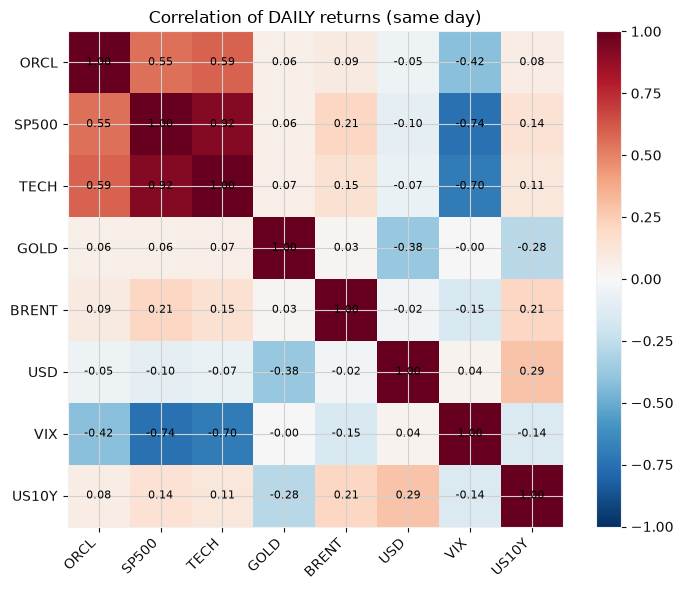

In [14]:
returns = pd.DataFrame(index=data.index)
returns[config.TARGET_TICKER] = np.log(data["Close"]).diff()
for name in ["SP500", "TECH", "GOLD", "BRENT", "USD", "VIX"]:
    returns[name] = np.log(data[name]).diff()
returns["US10Y"] = data["US10Y"].diff()
returns = returns.dropna()

correlation = returns.corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
image = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation))); ax.set_xticklabels(correlation.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlation))); ax.set_yticklabels(correlation.columns)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(image)
ax.set_title("Correlation of DAILY returns (same day)")
plt.tight_layout()
plt.show()

**Our finding:** On the same day, Oracle's returns are most closely linked with the technology fund (TECH, 0.59) and the S&P 500 (0.55). Oracle moves in the opposite direction to the VIX (-0.42): when fear in the market rises, Oracle tends to fall. Gold (0.06), Brent (0.09), the US dollar (-0.05) and the 10-year yield (0.08) show almost no link with Oracle's daily returns.

Even the strongest links are only moderate. The S&P 500 and the technology fund move almost together (0.92), but Oracle's correlation with either is below 0.6. A correlation of 0.59 means the technology fund explains only about a third of Oracle's daily movement (0.59 squared is about 0.35). The rest comes from Oracle's own news, such as its earnings reports.

These are same-day relationships, so they are not a forecast. We only know today's market moves at the close, at the same moment as Oracle's own price. Notebook 4 tests whether today's predictor values help to forecast tomorrow's Oracle return, and that link is likely to be much weaker than the ones shown here.

## Summary

- The Oracle data covers 2,981 trading days, from 2 January 2015 to 9 November 2026. It is clean: no missing values, duplicate dates, bad prices or days with zero volume.
- There are 18 days with moves of more than 10%. All of them are real events, mainly quarterly earnings reports (10 days) and the March 2020 COVID crash (3 days), so we keep them. 11 of the 18 happened from 2024 onwards.
- Oracle's price was calm from 2015 to 2022 and became far more volatile from 2023, when it became an AI cloud stock: it peaked above 300 in September 2025 and ended near 120. The price trends, so it is not stationary.
- Daily returns move around zero (about 0.04% a day) with a typical move of about 2%. They show volatility clustering and fat tails, so we forecast returns, not prices.
- On the same day, Oracle moves most with the technology fund (0.59) and the S&P 500 (0.55), and against the VIX (-0.42). This does not show that these predictors can forecast the next day.